# 01 · Data Exploration — UCDP GED, Ukraine Scope

Profiles the Ukraine-as-party subset of UCDP GED v25.1 (2022–2024) to:

1. Quantify the source-outlet distribution and inform the affiliation mapping.
2. Sanity-check the filtered subset against the project specification.

All loading and filtering logic lives in `src/rag_ucdp/data_loading.py`; this
notebook orchestrates calls to it and presents the results.

Profiling the source-outlet distribution here directly informs `config/source_affiliations.yaml` — a hand-curated lookup table that assigns each major outlet to a political/institutional category (e.g., `russian_state`, `ukrainian_state_aligned`, `international_independent`, `osint_volunteer`). That YAML is consumed by `src/rag_ucdp/source_bias.py`, which at retrieval time tags every event with its affiliation, computes diversity metrics over the result set, and surfaces a UI warning when a single affiliation cluster dominates. This empirical step matters because the actual top-30 outlets differ from the project spec's initial sketch — Mediazona is Russian but independent/critical, not state-aligned, for example — and the ~900-outlet long tail needs to fall to a sensible default rather than being classified one-by-one. In short: the notebook decides which outlets matter and what categories the data actually requires; the YAML encodes the decision; `source_bias.py` operationalizes it.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from collections import Counter
from pathlib import Path

import pandas as pd

from rag_ucdp.data_loading import (
    add_derived_columns,
    filter_to_ukraine_scope,
    load_raw_ucdp,
)

raw = load_raw_ucdp(Path("../data/raw/GEDEvent_v25_1.csv"))
ukr = filter_to_ukraine_scope(
    raw,
    conflict_parties_include=["Ukraine", "Government of Ukraine"],
    date_start="2022-01-01",
    date_end="2025-12-31",
)
df = add_derived_columns(ukr)

print(f"Raw events globally:        {len(raw):>10,}")
print(f"Ukraine as party, 2022-25:  {len(df):>10,}")
print(f"Columns available:          {len(df.columns):>10}")

Raw events globally:           385,918
Ukraine as party, 2022-25:      28,531
Columns available:                  51


<Axes: >

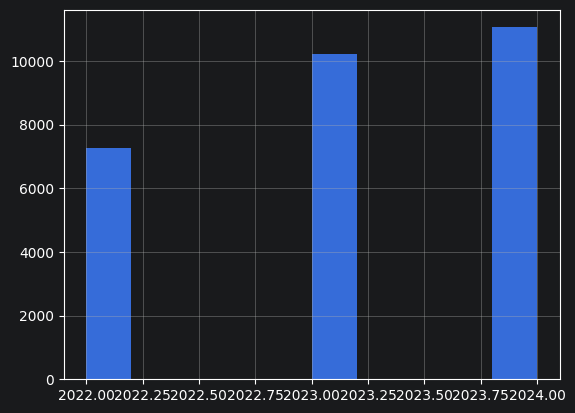

In [3]:
import matplotlib as plt
df["year"].hist()

## Source outlet distribution

Each event has a `source_office` field — a `;`-separated list of news outlets.
We've already parsed this into `source_office_list` (one event → list of outlet
strings). To rank outlets globally, flatten across all events and count.

In [4]:
all_sources: list[str] = []
for outlets in df["source_office_list"]:
    all_sources.extend(outlets)

source_counts = Counter(all_sources)

print(f"Total source mentions: {sum(source_counts.values()):,}")
print(f"Unique outlets:        {len(source_counts):,}\n")
print("Top 30 outlets:")
for i, (name, n) in enumerate(source_counts.most_common(30), 1):
    print(f"  {i:>2}. {name[:55]:<55} {n:>6,}")

Total source mentions: 37,854
Unique outlets:        963

Top 30 outlets:
   1. ITAR-TASS                                                9,393
   2. UA Losses                                                7,929
   3. Ukrinform                                                6,107
   4. Russo-Ukrainian Warspotting                              3,425
   5. Ukrinform: news                                          1,892
   6. Mediazona                                                1,503
   7. ELECTRONIC PETITIONS  Official online representation of  1,493
   8. fallenukraineheroes.info                                   426
   9. Reporting from Ukraine                                     411
  10. Militarnyi                                                 355
  11. Obozrevatel                                                294
  12. UALosses                                                   293
  13. Suspilne                                                   282
  14. Fallen Heroes Of Ukrain

## Sources per event

How many outlets corroborate a typical event? Low numbers mean we cannot rely
on intra-event cross-source diversity — diversity must come from the retrieval
layer (across multiple retrieved events) instead.

In [5]:
src_per_event = df["source_office_list"].apply(len)
print(f"Min:    {src_per_event.min()}")
print(f"Median: {src_per_event.median():.0f}")
print(f"Mean:   {src_per_event.mean():.2f}")
print(f"Max:    {src_per_event.max()}")
print(f"\nDistribution (top 10):")
for n_sources, count in sorted(Counter(src_per_event).items())[:10]:
    pct = 100 * count / len(df)
    print(f"  {n_sources} source(s): {count:>6,} events ({pct:5.1f}%)")

Min:    1
Median: 1
Mean:   1.33
Max:    149

Distribution (top 10):
  1 source(s): 22,972 events ( 80.5%)
  2 source(s):  3,893 events ( 13.6%)
  3 source(s):    928 events (  3.3%)
  4 source(s):    424 events (  1.5%)
  5 source(s):    112 events (  0.4%)
  6 source(s):     76 events (  0.3%)
  7 source(s):     45 events (  0.2%)
  8 source(s):     14 events (  0.0%)
  9 source(s):     19 events (  0.1%)
  10 source(s):     14 events (  0.0%)


## Long tail of the distribution

How concentrated is the data? If a small number of outlets cover most events,
the affiliation mapping only needs to handle those — we can lump the long tail
into a single `other` category.

In [6]:
total = sum(source_counts.values())
for k in (10, 30, 100, 300):
    covered = sum(n for _, n in source_counts.most_common(k))
    pct = 100 * covered / total
    print(f"Top {k:>3} outlets: {covered:>6,} mentions ({pct:5.1f}% of total)")

Top  10 outlets: 32,934 mentions ( 87.0% of total)
Top  30 outlets: 35,548 mentions ( 93.9% of total)
Top 100 outlets: 36,619 mentions ( 96.7% of total)
Top 300 outlets: 37,186 mentions ( 98.2% of total)


## Implications for the affiliation mapping

1. **Top 30 outlets cover ~94% of all mentions** — that's the realistic target
   for a hand-curated mapping. Everything beyond goes into `other`/`unknown`.
2. **Median of 1 source per event** means source diversity must be measured
   across retrieved events, not within them.
3. **Near-duplicates in source names** (e.g., `UA Losses` vs `UALosses` vs
   `UA losses`; `Ukrinform` vs `Ukrinform: news`) require case-insensitive,
   whitespace-tolerant lookup in `source_bias.py`.
4. **The top-10 mix is not what we sketched in the spec.** It includes specialty
   trackers (UA Losses, fallenukraineheroes), OSINT projects (Warspotting,
   Reporting from Ukraine), and an unexpected entry from the Ukrainian
   presidential petitions site. The categories `russian_state` /
   `international_independent` etc. need refinement.

## Text field availability and length

Goal: validate that the document template we plan to use in `preprocessing.py`
produces text that (a) actually contains the fields we intend, and (b) fits
within BGE-large-en-v1.5's 512-token input window.

We want answers to four concrete questions:

1) How often are key text fields populated? (Empty fields can't help retrieval.)
2) What are typical text lengths? Will our concatenated documents fit BGE-large's 512-token limit?
3) How are events distributed across oblasts? Any cross-border surprises?
4) Any temporal gaps suggesting data quality issues?

In [7]:
text_fields = [
    "where_description", "source_headline", "source_article", "source_office",
    "conflict_name", "dyad_name", "adm_1", "adm_2", "where_coordinates",
]
print(f"{'Field':<22} {'Filled':>15} {'Pct':>7}")
for col in text_fields:
    non_empty = df[col].notna() & (df[col].astype(str).str.strip() != "")
    pct = 100 * non_empty.sum() / len(df)
    print(f"  {col:<22} {non_empty.sum():>6,} / {len(df):,} ({pct:5.1f}%)")

Field                           Filled     Pct
  where_description      27,714 / 28,531 ( 97.1%)
  source_headline        28,527 / 28,531 (100.0%)
  source_article         28,531 / 28,531 (100.0%)
  source_office          28,531 / 28,531 (100.0%)
  conflict_name          28,531 / 28,531 (100.0%)
  dyad_name              28,531 / 28,531 (100.0%)
  adm_1                  26,604 / 28,531 ( 93.2%)
  adm_2                  22,777 / 28,531 ( 79.8%)
  where_coordinates      28,531 / 28,531 (100.0%)


In [8]:
print(f"{'Field':<22} {'min':>6} {'median':>8} {'p90':>6} {'p99':>6} {'max':>8}")
for col in ["source_headline", "source_article", "where_description"]:
    s = df[col].dropna().astype(str).str.len()
    s = s[s > 0]
    print(f"  {col:<22} {s.min():>6} {int(s.median()):>8} "
          f"{int(s.quantile(0.9)):>6} {int(s.quantile(0.99)):>6} {s.max():>8}")

Field                     min   median    p90    p99      max
  source_headline             4       81    185    447    15007
  source_article             24      109    245    585    18447
  where_description           3       32     95    217      453


The max is dramatic — a handful of events have absurdly long concatenated headlines that we'll truncate.

In [9]:
def estimate_doc(row: pd.Series) -> str:
    parts = [
        f"Date: {row['date_start']}",
        f"Location: {row.get('where_coordinates', '')}, "
        f"{row.get('adm_2', '')}, {row.get('adm_1', '')}, {row.get('country', '')}",
    ]
    if pd.notna(row.get("where_description")) and str(row["where_description"]).strip():
        parts.append(f"Specific location: {row['where_description']}")
    parts.append(f"Conflict: {row.get('conflict_name', '')} ({row.get('dyad_name', '')})")
    parts.append(f"Parties: {row.get('side_a', '')} vs {row.get('side_b', '')}")
    parts.append(f"Type: {row.get('type_of_violence_label', '')}")
    parts.append(
        f"Fatalities (best estimate): {row.get('best', 0)} "
        f"(range: {row.get('low', 0)}-{row.get('high', 0)})"
    )
    if pd.notna(row.get("source_headline")) and str(row["source_headline"]).strip():
        parts.append(f"Headlines: {row['source_headline']}")
    return "\n".join(parts)

doc_lens = df.apply(estimate_doc, axis=1).str.len()
print(f"Chars:  median={int(doc_lens.median())}, p90={int(doc_lens.quantile(0.9))}, "
      f"p99={int(doc_lens.quantile(0.99))}, max={doc_lens.max()}")
# Rough conversion: ~4 chars per token for English.
print(f"Tokens: median={int(doc_lens.median())//4}, p99={int(doc_lens.quantile(0.99))//4}, "
      f"max={doc_lens.max()//4}")

over_512 = (doc_lens // 4 > 512).sum()
print(f"\nDocuments estimated to exceed 512 tokens: {over_512} ({100*over_512/len(df):.2f}%)")

Chars:  median=452, p90=612, p99=904, max=15376
Tokens: median=113, p99=226, max=3844

Documents estimated to exceed 512 tokens: 10 (0.04%)


A small handful of events exceed 512 tokens — we'll truncate them.

## Geographic distribution

Sanity-checks the party-based scope: events outside Ukraine confirm that
cross-border events were captured.

In [10]:
print("Events by country:")
print(df["country"].value_counts().to_string())

print("\nTop 15 oblasts (adm_1):")
print(df["adm_1"].value_counts().head(15).to_string())

Events by country:
country
Ukraine                  27753
Russia (Soviet Union)      777
Poland                       1

Top 15 oblasts (adm_1):
adm_1
Donetsk oblast                  13737
Kharkiv oblast                   3100
Kherson oblast                   2702
Luhansk oblast                   2331
Zaporizhzhya oblast              2289
Kursk oblast                      514
Sumy oblast                       352
Dnipropetrovsk oblast             325
Mykolayiv oblast                  268
Chernihiv oblast                  239
Belgorod oblast                   209
Kyiv oblast                       155
Odessa oblast                      83
Kyiv Special Republican city       55
Zhytomyr oblast                    36


Ukraine 27,753; Russia 777; Poland 1 (the Przewodów S-300 incident, Nov 2022). Top oblast is Donetsk at 13,737 (~48% of all events). Cross-border Russian oblasts Kursk (514) and Belgorod (209) confirmed.

## Temporal distribution

Validates that data is reasonably continuous through the date window and flags
any unexpected gaps.

In [11]:
import matplotlib.pyplot as plt

df_t = df.copy()
df_t["yearmonth"] = pd.to_datetime(df_t["date_start"]).dt.to_period("M")
monthly = df_t["yearmonth"].value_counts().sort_index()

print(f"Events per month: min={monthly.min()}, median={int(monthly.median())}, max={monthly.max()}")
print(f"Quietest month: {monthly.idxmin()} ({monthly.min()} events)")
print(f"Busiest month:  {monthly.idxmax()} ({monthly.max()} events)")
print(f"Months covered: {len(monthly)} (from {monthly.index.min()} to {monthly.index.max()})")

Events per month: min=15, median=761, max=1551
Quietest month: 2022-01 (15 events)
Busiest month:  2024-05 (1551 events)
Months covered: 36 (from 2022-01 to 2024-12)


### Time series of monthly conflict events

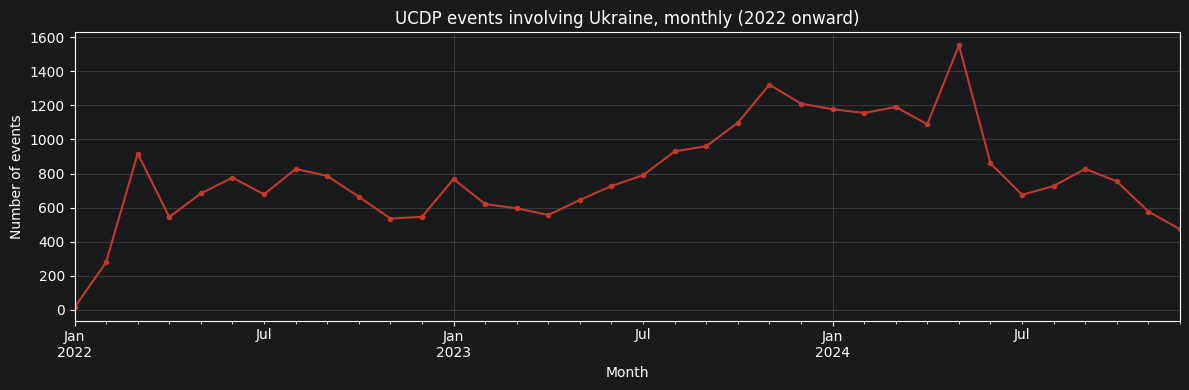

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
monthly.plot(ax=ax, kind="line", marker="o", markersize=3, linewidth=1.5, color="#c0392b")
ax.set_title("UCDP events involving Ukraine, monthly (2022 onward)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of events")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Seasonality: events per calendar month, averaged across years

If conflict intensity varies by season, we should see it here. The bar plot
groups every January together, every February together, etc., across the
full date window.

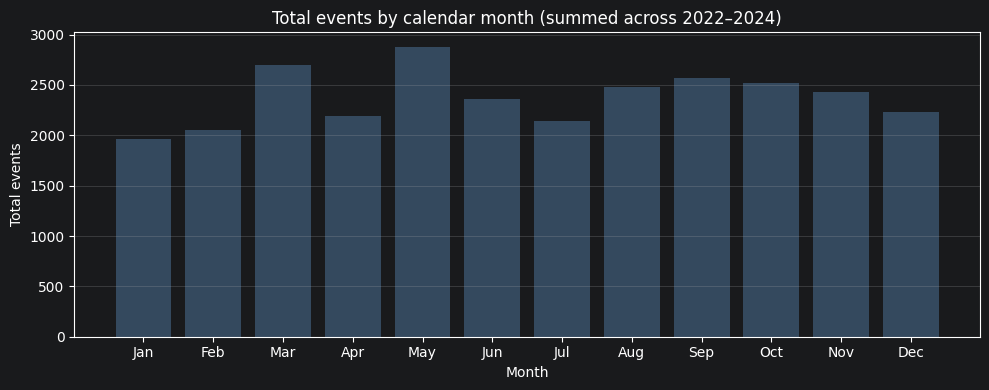

In [13]:
df_t["month"] = pd.to_datetime(df_t["date_start"]).dt.month
seasonal = df_t.groupby("month").size()
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(month_labels, seasonal.values, color="#34495e")
ax.set_title("Total events by calendar month (summed across 2022–2024)")
ax.set_xlabel("Month")
ax.set_ylabel("Total events")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Implications for `preprocessing.py`

1. **The document template fits BGE-large** at the median and p99. Only a
   small tail of extreme events exceeds 512 tokens; we'll handle them by
   truncating `source_headline` to a max character length (~800 chars).
2. **`where_description` is empty for ~3% of events** — `build_document` must
   conditionally include the "Specific location:" line, never insert empty
   placeholders.
3. **Cross-border scope is working as intended** — 777 Russian-territory events
   captured plus one Polish event (Przewodów, Nov 2022). All correctly
   identified as Ukraine-conflict events because Ukraine is one of the parties.
4. **Donetsk dominates** (~48% of all events). Retrieval over geographic
   queries needs to handle this concentration — a generic "events in Ukraine"
   query will overwhelmingly return Donetsk results. The router's metadata
   pre-filtering will mitigate this when queries specify an oblast.
5. **Data is dense** — median 761 events/month means even narrow time
   filters yield substantial result sets. This is good for retrieval quality
   but underscores the need for source diversity tracking.

## Persist the filtered subset

Save the filtered + enriched DataFrame to `data/processed/` so subsequent
phases (indexing, retrieval, eval) have a stable, reproducible input. The
Parquet file is small enough (~3.6 MB) to commit to the repo.

In [14]:
from rag_ucdp.data_loading import save_processed

output_path = Path("../data/processed/events_ukraine.parquet")
save_processed(df, output_path)
print(f"\nFile size: {output_path.stat().st_size / 1024 / 1024:.2f} MB")


File size: 3.61 MB
